**Лабораторная работа №1 - Иерархический кластерный анализ.**

Исходные данные содержат результаты опроса потребителей леденцов. Каждый респондент оценивал 11 утверждений (V1–V11), отражающих различные мотивы потребления: освежение дыхания, желание сладкого, улучшение самочувствия и другие.

Загрузим данные и проверим их размер, типы признаков, наличие пропусков и основные статистические характеристики.

In [30]:
import pandas as pd

df = pd.read_csv('Леденцы.dat', sep=';')
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [31]:
df.shape

(338, 11)

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


In [33]:
df.isnull().sum()

,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


In [34]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


В наборе данных 338 наблюдений и 11 числовых признаков. Пропущенные значения отсутствуют, все столбцы имеют тип int64.

Оценки находятся в диапазоне от 2 до 5. Средние значения признаков составляют примерно от 3,20 до 3,63, стандартные отклонения — от 0,87 до 0,99. Признаки измеряются по одной шкале, поэтому дополнительная стандартизация не проводилась.

**Иерархическая кластеризация**

Для разделения респондентов на группы используем метод Уорда с евклидовой метрикой. Он последовательно объединяет кластеры, минимизируя увеличение внутрикластерной суммы квадратов, что позволяет формировать группы с близкими оценками признаков.

Построим дендрограмму, чтобы изучить последовательность объединений и предварительно оценить возможное количество кластеров.

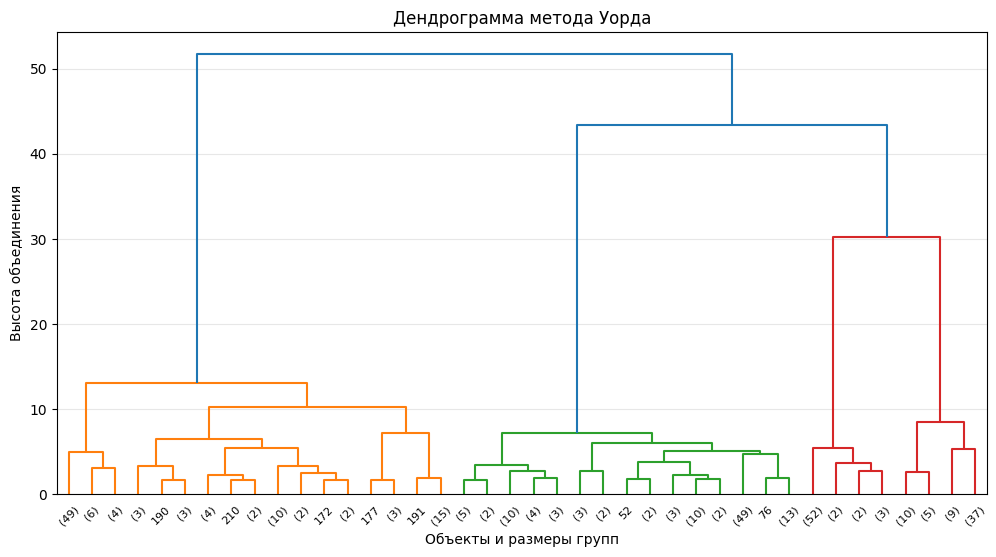

In [35]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Кластеризация методом Уорда
Z = linkage(df, method='ward', metric='euclidean')

# Построение дендрограммы
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=40)

plt.title('Дендрограмма метода Уорда')
plt.xlabel('Объекты и размеры групп')
plt.ylabel('Высота объединения')
plt.grid(axis='y', alpha=0.3)
plt.show()

По дендрограмме можно предварительно оценить структуру данных. Наибольшие объединения происходят на высотах около 30, 43 и 52. Для более обоснованного выбора количества кластеров рассчитаем коэффициент силуэта при разбиении на 2–10 групп.

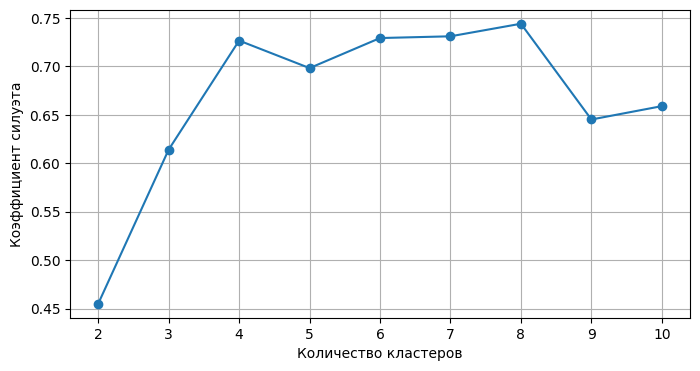

In [36]:
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score

scores = []

# Проверяем от 2 до 10 кластеров
for k in range(2, 11):
    labels = fcluster(Z, k, criterion='maxclust')
    score = silhouette_score(df, labels)
    scores.append(score)

# График коэффициента силуэта
plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), scores, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент силуэта')
plt.xticks(range(2, 11))
plt.grid()
plt.show()

Максимальный коэффициент силуэта получен при 8 кластерах (около 0,74). При 4 кластерах показатель составляет 0,727, что также указывает на хорошее разделение объектов. Сравним численность групп для обоих вариантов, чтобы оценить возможность их дальнейшей интерпретации.

In [37]:
# Количество респондентов в каждом кластере
for k in [4, 8]:
    labels = fcluster(Z, k, criterion='maxclust')
    print(f'\nКластеров: {k}')
    print(pd.Series(labels).value_counts().sort_index())



Кластеров: 4
1    108
2    110
3     59
4     61
Name: count, dtype: int64

Кластеров: 8
1     59
2     29
3      4
4     16
5    110
6     59
7     15
8     46
Name: count, dtype: int64


При разбиении на 4 кластера численность групп составляет 108, 110, 59 и 61 человек. При 8 кластерах появляются малочисленные группы, в том числе кластер из 4 человек.

Для дальнейшего анализа выбрано 4 кластера: коэффициент силуэта лишь немного ниже максимального, при этом все полученные группы достаточно многочисленны для содержательной интерпретации.

Для визуализации выбранного разбиения используем **метод главных компонент (PCA)**. Он позволит представить данные с 11 признаками на двумерном графике и посмотреть расположение полученных групп.

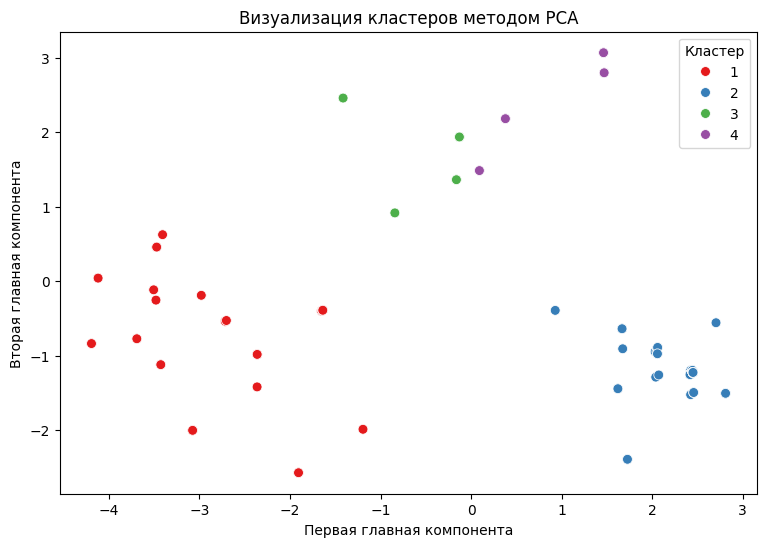

In [38]:
from sklearn.decomposition import PCA
import seaborn as sns

# Разделяем данные на 4 кластера
labels = fcluster(Z, 4, criterion='maxclust')

# Снижаем размерность до двух признаков
pca = PCA(n_components=2)
x = pca.fit_transform(df)

# Строим график кластеров
plt.figure(figsize=(9, 6))
sns.scatterplot(x=x[:, 0], y=x[:, 1], hue=labels, palette='Set1', s=50)
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Визуализация кластеров методом PCA')
plt.legend(title='Кластер')
plt.show()

In [39]:
# Доля дисперсии, объясняемая двумя компонентами
pca.explained_variance_ratio_.sum()

np.float64(0.7798351988951506)

Для визуализации кластеров размерность данных снижена с 11 признаков до двух методом PCA. На графике четыре группы респондентов занимают разные области. Часть точек накладывается друг на друга из-за совпадающих или близких значений признаков.

Первые две главные компоненты объясняют около 78% общей дисперсии данных. Таким образом, на двумерном графике сохраняется большая часть изменчивости исходных признаков, хотя часть информации при снижении размерности теряется.

In [40]:
# Разделяем респондентов на 4 кластера
labels = fcluster(Z, 4, criterion='maxclust')

# Средние оценки признаков по кластерам
result = df.copy()
result['Кластер'] = labels

means = result.groupby('Кластер').mean()
means.round(2)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Кластер,,,,,,,,,,,
1,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00
4,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75


Для интерпретации полученных групп рассчитаем средние значения признаков V1–V11 в каждом кластере. Это позволит определить основные мотивы потребления леденцов для каждой группы.

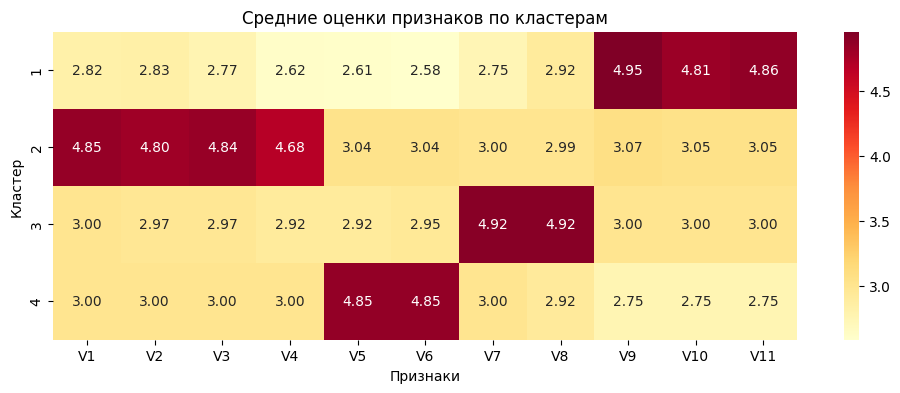

In [41]:
import seaborn as sns

# Средние оценки по кластерам
plt.figure(figsize=(12, 4))
sns.heatmap(means, annot=True, fmt='.2f', cmap='YlOrRd')
plt.xlabel('Признаки')
plt.ylabel('Кластер')
plt.title('Средние оценки признаков по кластерам')
plt.show()


### Интерпретация кластеров

В результате иерархической кластеризации выделено 4 группы потребителей.

- **Кластер 1 (108 человек).** Наиболее высокие оценки по V9–V11. Основной мотив потребления — облегчение симптомов заболеваний и улучшение самочувствия;
- **Кластер 2 (110 человек).** Преобладают оценки V1–V4. Леденцы используются преимущественно для освежения дыхания и полости рта;
- **Кластер 3 (59 человек).** Наиболее выражены V7 и V8. Потребление связано с концентрацией внимания и возможностью отвлечься;
- **Кластер 4 (61 человек).** Высокие оценки по V5 и V6. Леденцы воспринимаются преимущественно как сладость или замена другим кондитерским изделиям.

Проверим, насколько результаты зависят от выбранного метода объединения кластеров. Сравним методы Уорда, полной и средней связи по коэффициенту силуэта, а затем оценим совпадение полученных разбиений.

In [42]:
methods = ['ward', 'complete', 'average']

# Сравниваем методы кластеризации
for method in methods:
    z = linkage(df, method=method, metric='euclidean')
    labels = fcluster(z, 4, criterion='maxclust')
    score = silhouette_score(df, labels)
    print(method, round(score, 3))


ward 0.727
complete 0.727
average 0.727


In [43]:
from sklearn.metrics import adjusted_rand_score

# Сравниваем полученные разбиения
a = fcluster(linkage(df, method='ward'), 4, criterion='maxclust')
b = fcluster(linkage(df, method='complete'), 4, criterion='maxclust')
c = fcluster(linkage(df, method='average'), 4, criterion='maxclust')

print('Ward и Complete:', adjusted_rand_score(a, b))
print('Ward и Average:', adjusted_rand_score(a, c))

Ward и Complete: 1.0
Ward и Average: 1.0


При сравнении методов Уорда, полной и средней связи коэффициент силуэта во всех случаях составил 0,727. Сравнение разбиений с помощью скорректированного индекса Рэнда (ARI) показало полное совпадение кластеров (ARI = 1). Для дальнейшего анализа оставлен метод Уорда.

**Вывод**

Проведена иерархическая кластеризация 338 респондентов по 11 признакам методом Уорда с евклидовой метрикой.

Для определения числа кластеров использовались дендрограмма и коэффициент силуэта. Выбрано разбиение на 4 кластера с коэффициентом силуэта 0,727. Хотя при 8 кластерах показатель выше, некоторые группы оказались малочисленными.

Выделены четыре группы потребителей с различными мотивами употребления леденцов: лечебными, гигиеническими, связанными с концентрацией и желанием сладкого. Сравнение методов Уорда, полной и средней связи показало совпадение разбиений на четыре кластера (ARI = 1).